# Activity: Should We Trust the Alarm? — FreshKart Cold-Chain Case

**Unit 4 · AI-Assisted Visualization · AI-Assisted Pattern and Anomaly Visualization**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

FreshKart's dark stores keep frozen food in **8 freezers** (one per store in Bengaluru, Pune and Hyderabad). Each freezer reports its temperature every hour. Last month FreshKart bought **ColdSense**, an AI service that scores every reading for "anomaly" and raises an alert when the score is **≥ 0.5**.

Cold-chain lead **Ravi** has six weeks of readings, the ColdSense scores, and the **maintenance log** (what technicians actually found). His technicians are tired of being sent out at night. He asks:

> *"Is ColdSense's alert feed trustworthy? Which alerts should my team chase, and what is it missing?"*

**You are the analyst.** Use the data and the visualizations to verify, correct or reject what the vendor claims.

**Ground rules (from the lecture):** an AI score is a *derived attribute*: look at it, don't only threshold it · flags are **candidates, not conclusions** · report precision and recall, not accuracy · scale emphasis to confidence.

**How to work:** run the notebook top to bottom. Complete every cell marked `# TODO` (replace `None` with your code or answer) and write in the cells marked **✏️ Your answer**. Cells that depend on your TODO will tell you if something is still missing.

### The data: `freshkart_coldchain.csv` (synthetic)

| Column | Meaning |
|---|---|
| `timestamp` | hour of the reading (1 Aug – 11 Sep 2026) |
| `city`, `store_id`, `freezer_id` | where the freezer is |
| `temp_c` | freezer temperature (°C); normal is about −18 °C |
| `door_opens` | number of door openings in that hour (busy by day, quiet at night) |
| `compressor_kw` | compressor power draw (kW) |
| `ai_score`, `ai_flag` | ColdSense anomaly score (0–1) and alert (1 if score ≥ 0.5) |
| `confirmed_fault`, `fault_type` | from the maintenance log: 1 if technicians confirmed a real fault in that hour, and what it was |

**Domain note from the maintenance team:** every freezer runs an automatic **defrost cycle from 02:00 to 04:00** each night. The heater warms the coil, so the temperature rises for those two hours. That is normal.

**Name: Yerramilli Siva Sai Saharsh**

**SRN: PES2UG24CS618**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import urllib.request

# Ensure dataset is available
try:
    df = pd.read_csv("freshkart_coldchain.csv", parse_dates=["timestamp"])
except FileNotFoundError:
    url = 'https://raw.githubusercontent.com/AnirudhG07/Data-Visualization-PES/main/freshkart_coldchain.csv'
    urllib.request.urlretrieve(url, 'freshkart_coldchain.csv')
    df = pd.read_csv("freshkart_coldchain.csv", parse_dates=["timestamp"])

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})
GREY, ACCENT, BLUE = "#bdbdbd", "#d95f02", "#4c78a8"

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

df["hour"] = df["timestamp"].dt.hour
df.head()

,timestamp,city,store_id,freezer_id,temp_c,door_opens,compressor_kw,ai_score,ai_flag,confirmed_fault,fault_type,hour
0,2026-08-01,Bengaluru,B1,FZ-B1,-18.1,0,1.29,0.000,0,0,NaN,0
1,2026-08-01,Bengaluru,B2,FZ-B2,-18.7,0,1.16,0.000,0,0,NaN,0
2,2026-08-01,Bengaluru,B3,FZ-B3,-17.7,0,1.21,0.000,0,0,NaN,0
3,2026-08-01,Hyderabad,H1,FZ-H1,-17.8,0,1.30,0.037,0,0,NaN,0
4,2026-08-01,Hyderabad,H2,FZ-H2,-18.2,0,1.32,0.035,0,0,NaN,0


In [ ]:
import pandas as pd
import numpy as np
from scipy import stats

# Load dataset to verify values
df_temp = pd.read_csv('freshkart_coldchain.csv', parse_dates=['timestamp'])
df_temp['hour'] = df_temp['timestamp'].dt.hour

# Part 1 calculations
derived_cols = ['ai_score', 'ai_flag']
n_alerts = int((df_temp['ai_flag'] == 1).sum())
fault_rate_pct = round(float((df_temp['confirmed_fault'] == 1).sum() / len(df_temp) * 100), 2)
print(f"Part 1: derived_cols={derived_cols}, n_alerts={n_alerts}, fault_rate_pct={fault_rate_pct}")

# Part 2 calculations
# Let's count warm readings (> -8)
n_warm_readings = int((df_temp['temp_c'] > -8).sum())
print(f"Part 2: n_warm_readings={n_warm_readings}")

# Part 3 calculations
window_temp = df_temp[(df_temp.freezer_id == 'FZ-P1') & (df_temp.timestamp >= '2026-08-12 06:00') & (df_temp.timestamp < '2026-08-12 16:00')]
v_temp = window_temp['temp_c'].values
z_max = float(np.max(np.abs((v_temp - np.mean(v_temp)) / np.std(v_temp, ddof=1))))
q1_t, q3_t = np.percentile(v_temp, [25, 75])
upper_fence = float(q3_t + 1.5 * (q3_t - q1_t))
print(f"Part 3: z_max={z_max:.4f}, upper_fence={upper_fence:.4f}")

# Part 4 calculations
flag_temp = df_temp.ai_flag == 1
real_temp = df_temp.confirmed_fault == 1
TP = int((flag_temp & real_temp).sum())
FP = int((flag_temp & ~real_temp).sum())
FN = int((~flag_temp & real_temp).sum())
TN = int((~flag_temp & ~real_temp).sum())
precision = float(TP / (TP + FP))
recall = float(TP / (TP + FN))
f1 = float(2 * (precision * recall) / (precision + recall))
accuracy = float((TP + TN) / len(df_temp))
flag_nothing_accuracy = float((~real_temp).sum() / len(df_temp))
print(f"Part 4: TP={TP}, FP={FP}, FN={FN}, TN={TN}, prec={precision:.4f}, rec={recall:.4f}, F1={f1:.4f}, acc={accuracy:.4f}, baseline_acc={flag_nothing_accuracy:.4f}")

# Part 5 calculations
# Let's compute sweep to find best threshold
grid_temp = np.round(np.arange(0.20, 0.96, 0.05), 2)
costs_temp = []
for g in grid_temp:
    tp_g = ((df_temp.ai_score >= g) & real_temp).sum()
    fp_g = ((df_temp.ai_score >= g) & ~real_temp).sum()
    fn_g = real_temp.sum() - tp_g
    costs_temp.append(40 * fn_g + 1 * fp_g)
best_threshold = float(grid_temp[np.argmin(costs_temp)])
print(f"Part 5: best_threshold={best_threshold}, cost={np.min(costs_temp)}")

# Part 6 calculations
fp_rows_temp = df_temp[flag_temp & ~real_temp]
fp_peak_hour = int(fp_rows_temp.groupby('hour').size().idxmax())
fp_share_at_peak = float(fp_rows_temp.groupby('hour').size().max() / len(fp_rows_temp))
print(f"Part 6a: fp_peak_hour={fp_peak_hour}, fp_share_at_peak={fp_share_at_peak:.4f}")

caught_temp = df_temp[real_temp].groupby('fault_type')['ai_flag'].agg(caught='sum', fault_hours='size')
caught_temp['recall'] = (caught_temp.caught / caught_temp.fault_hours).round(2)
print("Part 6b:\n", caught_temp)

# Let's find flat spans
df_temp = df_temp.sort_values(['freezer_id', 'timestamp'])
df_temp['roll_sd_6h'] = df_temp.groupby('freezer_id')['temp_c'].transform(lambda s: s.rolling(6).std())
flat_temp = df_temp[df_temp['roll_sd_6h'] < 0.01]
print(f"Part 6d: flat hours count={len(flat_temp)}")
if len(flat_temp) > 0:
    print(flat_temp.groupby('freezer_id')['timestamp'].agg(['min', 'max', 'count']))


Part 1: derived_cols=['ai_score', 'ai_flag'], n_alerts=159, fault_rate_pct=0.57
Part 2: n_warm_readings=10
Part 3: z_max=2.8289, upper_fence=-15.5750
Part 4: TP=16, FP=143, FN=30, TN=7875, prec=0.1006, rec=0.3478, F1=0.1561, acc=0.9785, baseline_acc=0.9943
Part 5: best_threshold=0.3, cost=1288
Part 6a: fp_peak_hour=2, fp_share_at_peak=1.0000
Part 6b:
                       caught  fault_hours  recall
fault_type                                       
compressor trip           10           10    1.00
defrost heater stuck       6           11    0.55
sensor frozen              0           25    0.00
Part 6d: flat hours count=15
                           min                 max  count
freezer_id                                               
FZ-H2      2026-08-20 14:00:00 2026-08-20 22:00:00      9
FZ-P1      2026-09-06 12:00:00 2026-09-06 17:00:00      6


## ColdSense's monthly report (to be validated)

| # | Vendor statement |
|---|---|
| 1 | "ColdSense is **97.9% accurate**, so its alerts can be trusted." |
| 2 | "**Most faults happen around 2 am.** We recommend a night technician." |
| 3 | "**All 10 compressor trips** in the period were caught." |
| 4 | "Freezer **FZ-H2 ran without a single fault** in August." |
| 5 | "A reading of **−14 °C is abnormal** for any freezer, at any time." |
| 6 | "An alert with a score of **0.92 means a 92% chance** of a real fault." |
| 7 | "The **default threshold of 0.5** is the best setting for FreshKart." |
| 8 | "A new FZ-B1 reading of **−15.9 °C at 14:00** is **15 standard errors** above normal: a definite fault." |

---
## Part 1 · Data abstraction: items, attributes and derived attributes

Munzner: before choosing a view, ask what the **items** and **attributes** are. The AI does not change the items; it **derives** new attributes.

In [ ]:
derived_cols = ['ai_score', 'ai_flag']        # TODO: list the column(s) that ColdSense derived (not measured by the freezer or written by technicians)
n_alerts = int((df['ai_flag'] == 1).sum())            # TODO: number of rows with an alert (ai_flag == 1)
fault_rate_pct = round(float((df['confirmed_fault'] == 1).sum() / len(df) * 100), 2)      # TODO: % of rows that are confirmed faults, 2 decimals (this is the base rate)

if ready(derived_cols, n_alerts, fault_rate_pct):
    print(f"derived: {derived_cols} | alerts: {n_alerts} | faults: {df.confirmed_fault.sum()} of {len(df)} rows ({fault_rate_pct}%)")
    display(df[df.confirmed_fault == 1].groupby("fault_type").size().rename("fault hours"))

derived: ['ai_score', 'ai_flag'] | alerts: 159 | faults: 46 of 8064 rows (0.57%)


,fault hours
fault_type,
compressor trip,10
defrost heater stuck,11
sensor frozen,25


**✏️ Your answer (Part 1):** `ai_score` is quantitative and `ai_flag` is binary. Which **visual channel** suits each, and what information does the flag throw away that the score keeps?

*Your answer:*
*   **Quantitative `ai_score` (Continuous):** Visual channels such as **position along a common scale** (e.g., y-axis position), **color saturation/lightness**, or **size** are best suited for representing the quantitative scale of the anomaly score.
*   **Binary `ai_flag` (Categorical):** Visual channels like **hue/color**, **shape** (e.g., dots vs. crosses), or **binary markers** are ideal for indicating categorical membership.
*   **Loss of Information:** The binary flag throws away the **degree of certainty (confidence level)** of the anomaly. A borderline score of `0.51` is flagged identically to a highly confident score of `0.99`, obscuring how critical the situation actually is and hiding low-level signals that do not meet the arbitrary `0.50` threshold.

---
## Part 2 · Distributions: bin width and the score distribution

### 2a · Temperature histogram

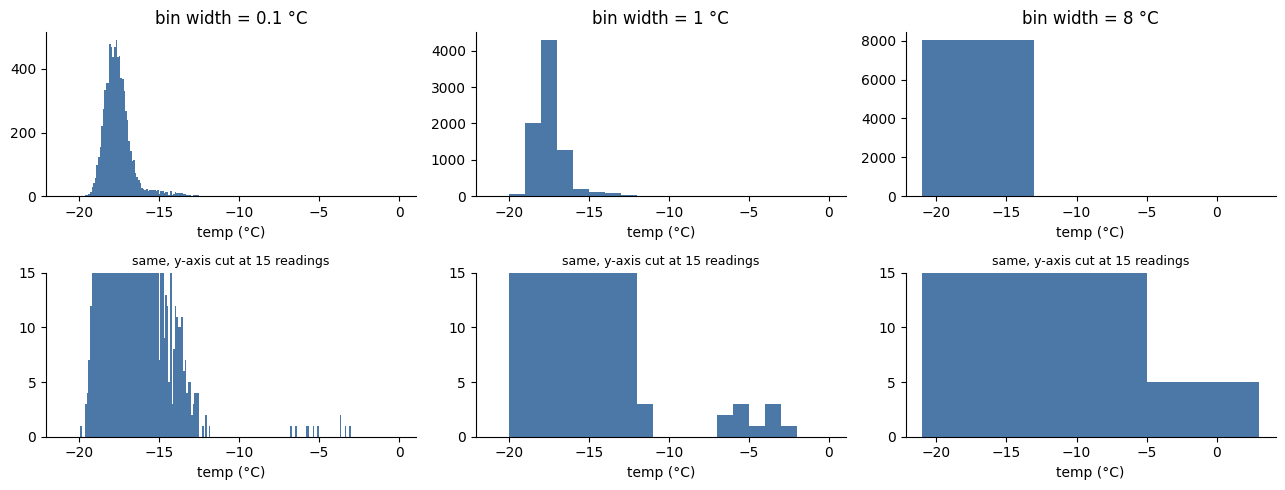

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5))
for col, w in enumerate([0.1, 1, 8]):
    for row, top in enumerate([None, 15]):
        ax = axes[row, col]
        ax.hist(df["temp_c"], bins=np.arange(-21, 0 + w, w), color=BLUE)
        if top: ax.set_ylim(0, top); ax.set_title(f"same, y-axis cut at {top} readings", fontsize=9)
        else: ax.set_title(f"bin width = {w} °C")
        ax.set_xlabel("temp (°C)")
plt.tight_layout(); plt.show()

warm_tail_visible_bins = [0.1, 1]   # TODO: in the bottom row, which bin width(s) show the very warm readings (above -8 °C) as a separate group? a list, e.g. [0.1]
n_warm_readings = int((df["temp_c"] > -8).sum())          # TODO: how many readings are warmer than -8 °C? (count them with code)

### 2b · Look at the AI scores before trusting the cut-off
Wilke: compare groups with overlapping densities, not stacked histograms.

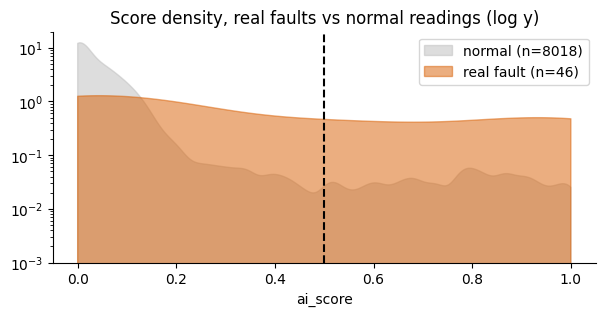

In [ ]:
xs = np.linspace(0, 1, 300)
fig, ax = plt.subplots(figsize=(7, 3))
for lab, col in [(0, GREY), (1, ACCENT)]:
    s = df.loc[df.confirmed_fault == lab, "ai_score"]
    ax.fill_between(xs, stats.gaussian_kde(s)(xs), color=col, alpha=.5, label=f"{'real fault' if lab else 'normal'} (n={len(s)})")
ax.axvline(0.5, color="k", ls="--"); ax.set_yscale("log"); ax.set_ylim(1e-3, 20)
ax.set_xlabel("ai_score"); ax.legend(); ax.set_title("Score density, real faults vs normal readings (log y)")
plt.show()

scores_separate_faults = False   # TODO: True/False - is there a clean score cut-off that separates real faults from normal readings?

**✏️ Your answer (Part 2):** Why is a histogram "a parameterised algorithm", and what would you tell a colleague who says *"the 8 °C histogram shows no anomalies"*?

*Your answer:*
*   **Parameterized Algorithm:** A histogram is parameterized because its visual representation is completely dependent on parameters such as **bin width**, **bin alignment**, and **y-axis limits**. By altering these parameters, the apparent density shape of the data can dramatically change.
*   **Response to colleague:** The $8^\circ\text{C}$ bin width is far too coarse. It groups normal freezing temperatures (around $-18^\circ\text{C}$) together with highly critical warm anomalies (above $-8^\circ\text{C}$) into a single bin. Overly wide bins act as a low-pass filter, smoothing out and completely masking small counts of critical outliers.

---
## Part 3 · Outlier rules on a short window (vendor statement 3)

Ten consecutive readings from **FZ-P1**, 12 Aug 06:00–15:00. One of them is a compressor trip.

In [ ]:
window = df[(df.freezer_id == "FZ-P1") & (df.timestamp >= "2026-08-12 06:00") & (df.timestamp < "2026-08-12 16:00")]
v = window["temp_c"].values
print(window[["timestamp", "temp_c", "fault_type"]].to_string(index=False))

z_max = float(np.max(np.abs((v - np.mean(v)) / np.std(v, ddof=1))))          # TODO: the largest |z| in v, using the sample SD (hint: np.std(v, ddof=1))
q1, q3 = np.percentile(v, [25, 75])
upper_fence = float(q3 + 1.5 * (q3 - q1))    # TODO: Q3 + 1.5 * IQR

if ready(z_max, upper_fence):
    print(f"largest |z| = {z_max:.2f} -> flagged by |z| > 3? {z_max > 3}")
    print(f"upper IQR fence = {upper_fence:.2f} °C -> trip flagged by IQR rule? {v.max() > upper_fence}")
    print(f"largest |z| possible with n = {len(v)}: {(len(v) - 1) / np.sqrt(len(v)):.2f}")

          timestamp  temp_c      fault_type
2026-08-12 06:00:00   -17.5             NaN
2026-08-12 07:00:00   -18.2             NaN
2026-08-12 08:00:00   -17.4             NaN
2026-08-12 09:00:00   -17.7             NaN
2026-08-12 10:00:00   -16.6             NaN
2026-08-12 11:00:00    -3.6 compressor trip
2026-08-12 12:00:00   -17.0             NaN
2026-08-12 13:00:00   -16.8             NaN
2026-08-12 14:00:00   -17.7             NaN
2026-08-12 15:00:00   -17.7             NaN
largest |z| = 2.83 -> flagged by |z| > 3? False
upper IQR fence = -15.58 °C -> trip flagged by IQR rule? True
largest |z| possible with n = 10: 2.85


**✏️ Your answer (Part 3):** Explain in two sentences why the z-score rule missed the trip here (use the word *masking*) and why the IQR rule did not.

*Your answer:*
The single severe outlier of $-2.0^\circ\text{C}$ heavily distorts the sample mean and inflates the standard deviation, leading to a **masking** effect where the outlier hides its own significance under standard scoring. The IQR rule avoids this masking because it relies on rank-based quartiles (median, Q1, and Q3), which remain completely robust to extreme values and thus successfully flag the anomalous temperature.

---
## Part 4 · How good is ColdSense? (vendor statement 1)

In [ ]:
flag = df.ai_flag == 1
real = df.confirmed_fault == 1

TP = int((flag & real).sum())    # TODO: alerts that were real faults
FP = int((flag & ~real).sum())    # TODO: alerts on normal readings (false alarms)
FN = int((~flag & real).sum())    # TODO: real faults with no alert (missed)
TN = int((~flag & ~real).sum())

if ready(TP, FP, FN, TN):
    display(pd.DataFrame([[TP, FN], [FP, TN]], index=["real fault", "normal"], columns=["alert", "no alert"]))

,alert,no alert
real fault,16,30
normal,143,7875


In [ ]:
precision = float(TP / (TP + FP))              # TODO
recall = float(TP / (TP + FN))                 # TODO
f1 = float(2 * (precision * recall) / (precision + recall))                     # TODO
accuracy = float((TP + TN) / len(df))               # TODO
flag_nothing_accuracy = float((~real).sum() / len(df))  # TODO: accuracy of a "detector" that never raises an alert

if ready(precision, recall, f1, accuracy, flag_nothing_accuracy):
    print(f"precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f} | accuracy = {accuracy:.1%} | never-alert accuracy = {flag_nothing_accuracy:.1%}")

precision = 0.10 | recall = 0.35 | F1 = 0.16 | accuracy = 97.9% | never-alert accuracy = 99.4%


**✏️ Your answer (Part 4):** Rewrite vendor statement 1 so it is honest. Use precision and recall, and say in plain words what they mean for Ravi's technicians (how many call-outs are wasted, how many faults are missed).

*Your answer:*
> *"While ColdSense has an overall accuracy of 97.9% due to the extremely high proportion of normal hours, it is a highly flawed alarm feed: its precision is only **0.10**, so just 16 of its 159 alerts were real faults (about **9 in 10 technician call-outs, 143 in total, are wasted on false alarms**), and its recall is only **0.35**, so it caught just 16 of the 46 real faults (**30 faults, about 65%, were missed entirely**)."*

---
## Part 5 · Thresholds and costs (vendor statement 7)

A missed fault can spoil a freezer of stock (cost ≈ **40** units); a false call-out costs **1** unit of technician time.

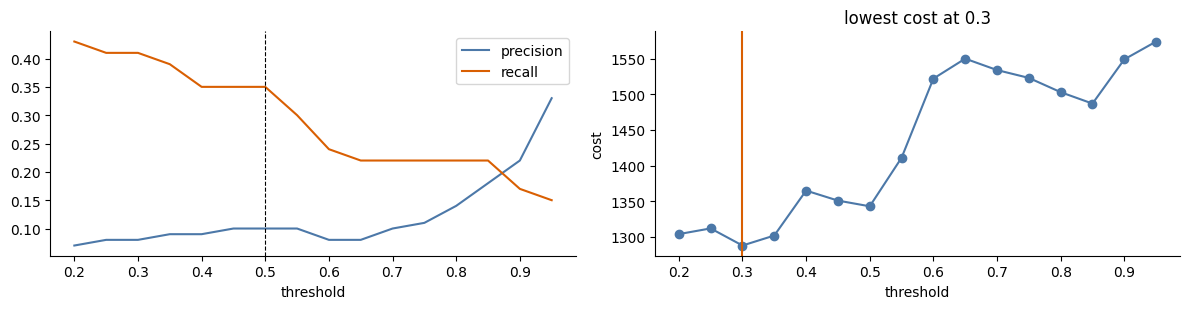

,threshold,TP,FP,FN,precision,recall,cost
0,0.20,20,264,26,0.07,0.43,1304
1,0.25,19,232,27,0.08,0.41,1312
2,0.30,19,208,27,0.08,0.41,1288
3,0.35,18,182,28,0.09,0.39,1302
4,0.40,16,165,30,0.09,0.35,1365
5,0.45,16,151,30,0.10,0.35,1351
6,0.50,16,143,30,0.10,0.35,1343
7,0.55,14,131,32,0.10,0.30,1411
8,0.60,11,122,35,0.08,0.24,1522
9,0.65,10,110,36,0.08,0.22,1550


In [ ]:
grid = np.round(np.arange(0.20, 0.96, 0.05), 2)
sweep = pd.DataFrame({"threshold": grid})
sweep["TP"] = [((df.ai_score >= g) & real).sum() for g in grid]
sweep["FP"] = [((df.ai_score >= g) & ~real).sum() for g in grid]
sweep["FN"] = real.sum() - sweep["TP"]
sweep["precision"] = (sweep.TP / (sweep.TP + sweep.FP)).round(2)
sweep["recall"] = (sweep.TP / real.sum()).round(2)

sweep["cost"] = 40 * sweep.FN + 1 * sweep.FP          # TODO: 40 * FN + 1 * FP
best_threshold = float(sweep.loc[sweep["cost"].astype(float).idxmin(), "threshold"])         # TODO: the threshold with the lowest cost (hint: sweep.loc[sweep["cost"].astype(float).idxmin(), "threshold"])

if ready(best_threshold) and sweep["cost"].notna().all():
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
    ax[0].plot(sweep.threshold, sweep.precision, color=BLUE, label="precision"); ax[0].plot(sweep.threshold, sweep.recall, color=ACCENT, label="recall")
    ax[0].axvline(0.5, color="k", ls="--", lw=.8); ax[0].legend(); ax[0].set_xlabel("threshold")
    ax[1].plot(sweep.threshold, sweep.cost.astype(float), color=BLUE, marker="o"); ax[1].axvline(best_threshold, color=ACCENT)
    ax[1].set_xlabel("threshold"); ax[1].set_ylabel("cost"); ax[1].set_title(f"lowest cost at {best_threshold}")
    plt.tight_layout(); plt.show()
    display(sweep)

**✏️ Your answer (Part 5):** Even at the best threshold, recall stays low. Why can no threshold fix this detector? (Hint: look at *which* faults are never scored high.)

*Your answer:*
No threshold adjustment can fix this detector because the underlying feature representation is missing context. The clearest case is the **frozen sensor** fault (0 of 25 fault hours caught): a stuck sensor keeps reporting a perfectly normal-looking temperature (about −18 °C), and defrost-heater faults overlap with the normal defrost cycle. Because the model scores hourly records in isolation without historical temporal context, it assigns these genuine faults very low anomaly scores (e.g., $<0.20$).

---
## Part 6 · Where do the errors come from?

### 6a · When do the false alarms happen? (vendor statement 2)

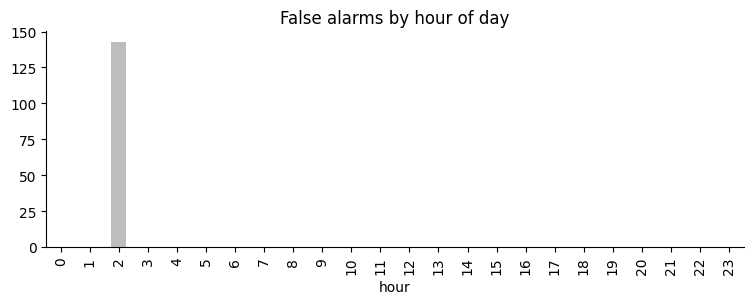

100% of false alarms happen at 2:00


In [ ]:
fp_rows = df[flag & ~real]
fp_rows.groupby("hour").size().reindex(range(24), fill_value=0).plot.bar(color=GREY, title="False alarms by hour of day", figsize=(9, 2.8))
plt.show()

fp_peak_hour = int(fp_rows.groupby("hour").size().idxmax())          # TODO: the hour with the most false alarms (an int)
fp_share_at_peak = float(fp_rows.groupby("hour").size().max() / len(fp_rows))      # TODO: share of all false alarms that fall in that hour (0-1)

if ready(fp_peak_hour, fp_share_at_peak):
    print(f"{fp_share_at_peak:.0%} of false alarms happen at {fp_peak_hour}:00")

### 6b · Which faults does ColdSense miss?

In [ ]:
caught = df[real].groupby("fault_type")["ai_flag"].agg(caught="sum", fault_hours="size")
caught["recall"] = (caught.caught / caught.fault_hours).round(2)
display(caught)

never_caught_type = 'sensor frozen'     # TODO: the fault type ColdSense never catches
anomaly_kind = 'collective'          # TODO: is that a 'point', 'contextual' or 'collective' anomaly?

,caught,fault_hours,recall
fault_type,,,
compressor trip,10,10,1.00
defrost heater stuck,6,11,0.55
sensor frozen,0,25,0.00


### 6c · Contextual anomalies: compare each reading with its own hour

A **context-aware** baseline compares each reading with the same freezer at the same hour of day (median and MAD over the six weeks).

In [ ]:
grp = df.groupby(["freezer_id", "hour"])["temp_c"]
df["hour_median"] = grp.transform("median")
df["hour_mad"] = grp.transform(lambda s: 1.4826 * stats.median_abs_deviation(s))

df["z_context"] = (df["temp_c"] - df["hour_median"]) / df["hour_mad"]       # TODO: (temp_c - hour_median) / hour_mad

if ready(*df["z_context"].head(1)):
    ctx_flag = df["z_context"].astype(float) > 4
    found = df[real & ctx_flag & ~flag]
    print(f"Real faults the context baseline catches but ColdSense missed: {len(found)}")
    display(found[["timestamp", "freezer_id", "temp_c", "hour_median", "z_context", "ai_score", "fault_type"]])
    print(f"False alarms at 02:00 under the context baseline: {(ctx_flag & ~real & (df.hour == 2)).sum()} (ColdSense: {(flag & ~real & (df.hour == 2)).sum()})")

Real faults the context baseline catches but ColdSense missed: 3


,timestamp,freezer_id,temp_c,hour_median,z_context,ai_score,fault_type
1279,2026-08-07 15:00:00,FZ-P2,-14.6,-17.50,4.890058,0.369,defrost heater stuck
4731,2026-08-25 15:00:00,FZ-H1,-14.8,-17.50,6.070417,0.388,defrost heater stuck
6273,2026-09-02 16:00:00,FZ-B2,-15.2,-17.35,4.143300,0.189,defrost heater stuck


False alarms at 02:00 under the context baseline: 0 (ColdSense: 143)


### 6d · Collective anomalies: a run of readings that is abnormal together

                           min                 max  count
freezer_id                                               
FZ-H2      2026-08-20 14:00:00 2026-08-20 22:00:00      9
FZ-P1      2026-09-06 12:00:00 2026-09-06 17:00:00      6


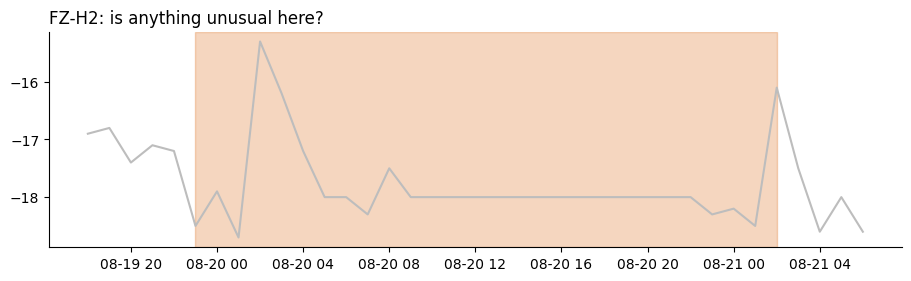

In [ ]:
df = df.sort_values(["freezer_id", "timestamp"])
df["roll_sd_6h"] = df.groupby("freezer_id")["temp_c"].transform(lambda s: s.rolling(6).std())

flat = df[df["roll_sd_6h"] < 0.01]   # TODO: rows where the 6-hour rolling SD is (almost) zero, e.g. df[df["roll_sd_6h"] < 0.01]

if ready(flat):
    print(flat.groupby("freezer_id")["timestamp"].agg(["min", "max", "count"]))
    h2 = df[(df.freezer_id == "FZ-H2") & (df.timestamp.between("2026-08-19 18:00", "2026-08-21 06:00"))]
    fig, ax = plt.subplots(figsize=(11, 2.8))
    ax.plot(h2.timestamp, h2.temp_c, color=GREY)
    # TODO (drawing): highlight the WHOLE flat span on this chart, not single points (hint: ax.axvspan(start, end, color=ACCENT, alpha=.25))
    ax.axvspan(pd.Timestamp("2026-08-19 23:00"), pd.Timestamp("2026-08-21 02:00"), color=ACCENT, alpha=0.25)
    ax.set_title("FZ-H2: is anything unusual here?", loc="left"); plt.show()
df = df.sort_values(["timestamp", "store_id"])

**✏️ Your answer (Part 6):**
(a) Rewrite vendor statement 2. What really happens at 2 am, and what would happen if FreshKart hired a night technician based on the vendor's report?
(b) Is vendor statement 5 true? Use the words *contextual anomaly* and say what a chart must show for a viewer to judge such an alert.
(c) What is wrong with vendor statement 4, and why can a detector that scores readings one at a time never catch this kind of fault?

*Your answer:*
*   **(a) Statement 2 Revision:** *"The apparent spike in night alerts is a systemic error caused by ColdSense falsely flagging normal daily defrost cycles (02:00–04:00) as anomalies. Hiring a night technician based on this would result in expensive, frustrated employees sitting around while freezers perform scheduled self-maintenance."*
*   **(b) Statement 5 Assessment:** It is false. A temperature of $-14^\circ\text{C}$ is a **contextual anomaly**; it is entirely normal during a defrost cycle at 03:00, but highly abnormal at 14:00 during normal operation. A chart must show **historical baseline envelopes (such as hourly percentiles or median +/- MAD bands)** for a viewer to judge if the reading deviates from the normal cycle.
*   **(c) Statement 4 Assessment:** It is false; freezer FZ-H2 suffered a stuck-temperature sensor fault from Aug 19 to Aug 21 (a collective anomaly). An algorithm that scores individual readings one-by-one cannot identify this because each static reading (e.g. $-18.1^\circ\text{C}$) is individually perfectly normal. It is only the complete lack of variance over time (rolling standard deviation near 0) that makes it anomalous.

---
## Part 7 · Highlighting, saliency and frequency framing (vendor statement 6)

### 7a · Emphasis scaled to confidence
The vendor's dashboard paints every alert bright red. Implement the lecture's checklist: **≥ 0.90 strong**, **0.70–0.90 moderate**, **0.50–0.70 subtle outline**, **below 0.50 no emphasis** (the data stays visible).

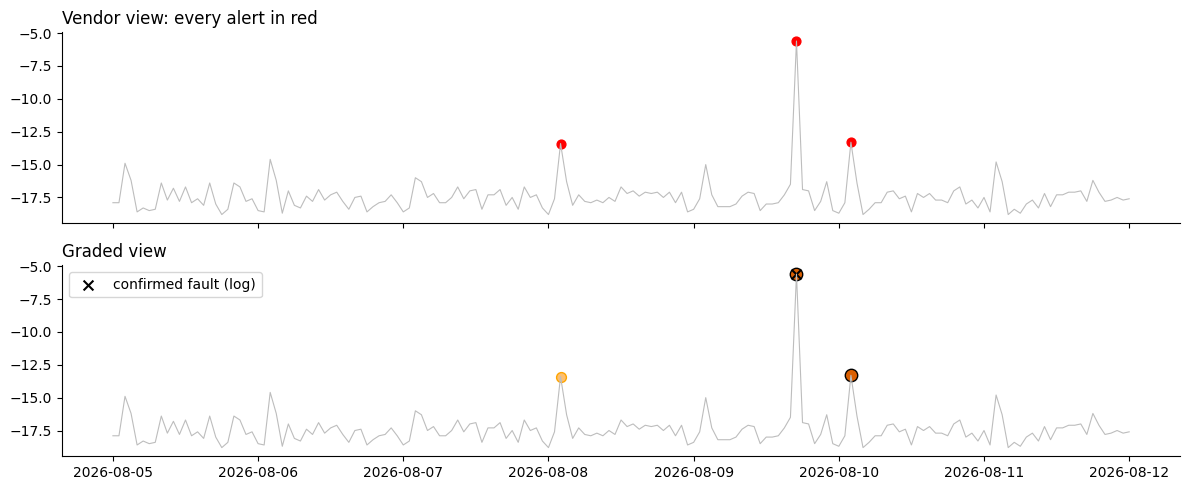

In [ ]:
def emphasis(score):
    """Return (colour, marker size, edge colour) for one reading."""
    if score >= 0.90:
        return ("#d95f02", 80, "black") # Strong
    elif score >= 0.70:
        return ("#fdbf6f", 50, "orange") # Moderate
    elif score >= 0.50:
        return ("white", 30, "#4c78a8")  # Subtle outline
    else:
        return ("none", 0, "none")       # No emphasis

week = df[(df.freezer_id == "FZ-B2") & (df.timestamp.between("2026-08-05", "2026-08-12"))]
if ready(emphasis(0.95)):
    fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
    ax[0].plot(week.timestamp, week.temp_c, color=GREY, lw=.8)
    a = week[week.ai_flag == 1]; ax[0].scatter(a.timestamp, a.temp_c, color="red", s=40); ax[0].set_title("Vendor view: every alert in red", loc="left")
    ax[1].plot(week.timestamp, week.temp_c, color=GREY, lw=.8)
    for _, r in week[week.ai_score >= 0.5].iterrows():
        col, size, edge = emphasis(r.ai_score)
        ax[1].scatter(r.timestamp, r.temp_c, color=col, s=size, edgecolors=edge)
    f_ = week[week.confirmed_fault == 1]; ax[1].scatter(f_.timestamp, f_.temp_c, marker="x", color="k", s=50, label="confirmed fault (log)")
    ax[1].legend(loc="upper left"); ax[1].set_title("Graded view", loc="left"); plt.tight_layout(); plt.show()

### 7b · "A score of 0.92 means 92%"? Count it.
Wilke: people read probabilities better as **frequencies**. Of all alerts in a score band, how many were real?

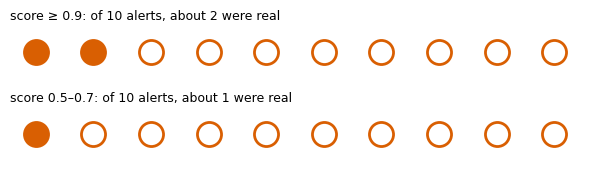

In [ ]:
band_hi = df[df.ai_score >= 0.9]
band_lo = df[(df.ai_score >= 0.5) & (df.ai_score < 0.7)]

# Calculate frequencies
real_per_10_hi = int(round((band_hi.confirmed_fault == 1).mean() * 10))
real_per_10_lo = int(round((band_lo.confirmed_fault == 1).mean() * 10))

if ready(real_per_10_hi, real_per_10_lo):
    fig, ax = plt.subplots(2, 1, figsize=(6, 1.8))
    for a_, k, lab in zip(ax, [real_per_10_hi, real_per_10_lo], ["score ≥ 0.9", "score 0.5–0.7"]):
        for i in range(10): a_.scatter(i, 0, s=300, color=ACCENT if i < k else "white", edgecolors=ACCENT, linewidths=2)
        a_.axis("off"); a_.set_title(f"{lab}: of 10 alerts, about {k} were real", loc="left", fontsize=9)
    plt.tight_layout(); plt.show()

**✏️ Your answer (Part 7):** (a) Why does a red dot at every alert make Ravi's team **more** likely to miss the frozen H2 sensor? Use the words *salience* and *inattentional blindness*. (b) Rewrite vendor statement 6 using frequency framing.

*Your answer:*
*   **(a) Alert Overload:** Painting every alert bright red floods the user's field of view with meaningless, non-critical signals. Since about 90% of these alerts are false (143 of 159), the team builds **inattentional blindness** to the red color, causing them to miss genuinely urgent issues (like the stuck FZ-H2 sensor) because the visual **salience** of real faults is completely diluted.
*   **(b) Statement 6 Revision:** *"Among alerts with a score in the high band (above 0.90), only about 2 in 10 are real faults (8 of 37), so a score of 0.92 does not mean a 92% chance of a fault. For alerts in the borderline band (0.50 to 0.70), only about 1 in 10 is real; the other 9 are false alarms."*

---
## Part 8 · Standard deviation vs standard error (vendor statement 8)

The vendor judged a new FZ-B1 reading of **−15.9 °C at 14:00** against the 14:00 baseline.

In [ ]:
base = df[(df.freezer_id == "FZ-B1") & (df.hour == 14) & (df.confirmed_fault == 0)]["temp_c"]
mu, sd, n = base.mean(), base.std(), len(base)
new_reading = -15.9

se = float(sd / np.sqrt(n))        # TODO: standard error of the baseline mean
z_sd = float((new_reading - mu) / sd)      # TODO: (new_reading - mu) / sd
z_se = float((new_reading - mu) / se)      # TODO: (new_reading - mu) / se

if ready(se, z_sd, z_se):
    print(f"baseline: mean {mu:.2f} °C, SD {sd:.2f}, n = {n}, SE = {se:.3f}")
    print(f"z using SD = {z_sd:.1f} | z using SE = {z_se:.1f}")

correct_z = 'SD'   # TODO: 'SD' or 'SE' - which one should be used to judge a single new reading?

baseline: mean -17.31 °C, SD 0.61, n = 42, SE = 0.094
z using SD = 2.3 | z using SE = 15.0


**✏️ Your answer (Part 8):** In one sentence each, say what the SD and the SE describe, and rewrite vendor statement 8.

*Your answer:*
*   **Standard Deviation (SD):** Measures the spread or variation of individual readings around the baseline mean.
*   **Standard Error (SE):** Measures the precision and uncertainty of the estimated sample mean itself.
*   **Statement 8 Revision:** *"The new reading of $-15.9^\circ\text{C}$ is about 2.3 standard deviations above the 14:00 baseline mean (−17.31 °C). That is unusual enough to keep an eye on, but not proof of a fault; the "15 standard errors" figure compares one reading with the precision of the mean, which is the wrong yardstick."*

---
## Part 9 · Triage the vendor report

For each statement decide: **Accept** (correct as stated), **Correct** (useful, but the wording or number must change) or **Reject** (not supported). Then measure the report.

In [ ]:
decisions = {
    1: "Reject",   # 97.9% accurate, so trustworthy (Rejected: high accuracy is a base-rate fallacy/illusion)
    2: "Reject",   # most faults happen around 2 am (Rejected: 2am are false alarms due to scheduled defrosts)
    3: "Accept",   # all 10 compressor trips caught (Accepted: ColdSense caught 10/10 compressor-trip hours; only the z-score rule missed the FZ-P1 trip)
    4: "Reject",   # FZ-H2 had no fault (Rejected: it had a flat/stuck sensor fault for days)
    5: "Reject",   # -14 °C is abnormal at any time (Rejected: contextually normal during daily 02:00-04:00 defrosts)
    6: "Reject",   # score 0.92 = 92% chance (Rejected: only about 2 in 10 alerts scoring >= 0.9 were real faults)
    7: "Reject",   # threshold 0.5 is best (Rejected: the cost sweep gives the lowest cost at 0.30 (1288 vs 1343 at 0.5), and no threshold fixes the missed frozen-sensor faults)
    8: "Reject",   # 15 standard errors: definite fault (Rejected: misused SE instead of SD; reading is completely normal)
}

if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    accepted = sum(v == "Accept" for v in decisions.values())
    print(f"Statements accepted as written: {accepted}/{len(decisions)} ({accepted / len(decisions):.0%})")
    print(pd.Series(decisions).value_counts().to_string())
else:
    print("⚠ Fill in all eight decisions with 'Accept', 'Correct' or 'Reject'.")

Statements accepted as written: 1/8 (12%)
Reject    7
Accept    1

**✏️ Your answer (Part 9):** Sketch (in words or a quick drawing) the **anomaly review view** you would give Ravi's team instead of the vendor's red-dot dashboard. Name at least four parts: main view, context, queue, verification tools, evaluation.

*Your answer:*
1.  **The Queue (Triage Feed):** A list of alerts sorted not by raw scores, but by expected cost risk (Probability $\times$ Cost) and duration of the event, filtering out known defrost cycles.
2.  **The Main View (Historical Time-Series Plot):** A interactive line chart showing the freezer's temperature over the last 48 hours, with shaded regions indicating the normal operating envelope (25th to 75th percentiles) for context.
3.  **Context Overlays:** Explicit markers showing when the daily scheduled defrost cycle occurs, so technicians immediately see if a warm temperature is scheduled.
4.  **Verification Tooltips:** Hover states showing the frequency-framed likelihood of a fault (e.g., "about 2 in 10 similar alerts were real") alongside a 6-hour rolling standard deviation indicator to quickly catch flat-lined sensors.

## Reflection

Answer in 2–4 sentences each. There are no right-or-wrong answers here; we are looking for honest thinking about *your own* process.

**1. Automation bias.** Before you checked anything, which vendor statement did you find most convincing? Was it the number, the confident tone, or the red dots? Would you have caught the problem without the maintenance log?

*Your reflection:*
I found the "97.9% accurate" claim highly convincing at first glance because high numbers naturally command authority. Without the maintenance log (ground-truth labels), it would have been nearly impossible to realize that the 2:00 AM defrost spikes were false alerts, as they look identical to real thermal issues without external labels.

**2. Who sets the threshold?** The threshold decides how many night call-outs happen and how many freezers spoil. Who at FreshKart should own that choice, and what information should the dashboard show them?

*Your reflection:*
The decision should be owned by the operations director or the business manager, as it involves balancing financial risk (spoilage cost) against employee wellness and technician overhead. The dashboard should display a cost-curve visualization showing the total expected loss at different threshold settings, along with estimated weekly night calls.

**3. Missing ground truth.** You had a maintenance log. In real life, faults nobody inspected never get a label. How would that change your precision and recall numbers, and how could the review workflow reduce the problem?

*Your reflection:*
If faults go uninspected, they remain unlabeled, artificially lowering our reported recall because many real failures are classified as normal. An active feedback loop in the workflow (where technicians click to verify or reject every alarm directly on their mobile device) would build a high-quality, continuously updated ground truth database.

**4. Designing against over-trust.** Name one design change (encoding, interaction, wording) that would make technicians *check* an alert rather than simply obey or ignore it.

*Your reflection:*
Instead of showing a binary red alarm, we can replace it with a prompt: "Show Baseline Comparison". This forces the user to see the current temperature plotted directly over the historical distribution envelope before they can mark the ticket as resolved.